<a href="https://colab.research.google.com/github/sashawrk4-pylyp/My-Python-Data-Analysis/blob/main/Data_Visualization_with_Seaborn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [44]:
# Connecting Google Drive
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [45]:
# Changing work folder
%cd /content/drive/MyDrive/**Jupyter**

[Errno 2] No such file or directory: '/content/drive/MyDrive/**Jupyter**'
/content


In [46]:
!find /content/drive/MyDrive/Jupyter -iname "*sales*"

/content/drive/MyDrive/Jupyter/sales_data_updated.gsheet
/content/drive/MyDrive/Jupyter/sales_data_updated - sales_data_updated.csv
/content/drive/MyDrive/Jupyter/sales.csv
/content/drive/MyDrive/Jupyter/sales_data.csv
/content/drive/MyDrive/Jupyter/sales3.ipynb
/content/drive/MyDrive/Jupyter/books_sales.ipynb
/content/drive/MyDrive/Jupyter/Online store sales.ipynb
/content/drive/MyDrive/Jupyter/Online store sales2
/content/drive/MyDrive/Jupyter/restaurant_sales.csv
/content/drive/MyDrive/Jupyter/Sales Comparison


In [47]:
# Завантаження CSV-файлу
sales_data = pd.read_csv("/content/drive/MyDrive/Jupyter/sales_data_updated - sales_data_updated.csv")

# Перегляд перших рядків
sales_data.head()

,order_date,time,aging,customer_id,gender,device_type,customer_login_type,product_category,product,sales,quantity,discount,profit,shipping_cost,order_priority,payment_method
0,2018-01-01,10:11:40,5.0,29317,Male,Web,Member,Auto & Accessories,Car Media Players,140.0,4.0,0.3,43.2,4.3,Medium,e_wallet
1,2018-01-01,22:30:44,7.0,42270,Male,Web,Member,Auto & Accessories,Car Pillow & Neck Rest,231.0,5.0,0.1,139.5,13.9,High,money_order
2,2018-01-01,21:55:31,10.0,14563,Male,Web,Member,Auto & Accessories,Car Speakers,211.0,5.0,0.1,120.5,12.0,High,credit_card
3,2018-01-01,13:57:15,9.0,58601,Male,Web,Member,Auto & Accessories,Tyre,250.0,4.0,0.2,150.0,15.0,Critical,credit_card
4,2018-01-01,15:17:41,2.0,48342,Male,Web,Member,Auto & Accessories,Tyre,250.0,1.0,0.1,165.0,16.5,High,credit_card


In [48]:
# Основні показники прибутку
print("Total Profit:", sales_data["profit"].sum())
print("Average Profit:", sales_data["profit"].mean())
print("Median Profit:", sales_data["profit"].median())
print("Minimum Profit:", sales_data["profit"].min())
print("Maximum Profit:", sales_data["profit"].max())

Total Profit: 3611186.5999999996
Average Profit: 70.40722558003509
Median Profit: 59.9
Minimum Profit: 0.5
Maximum Profit: 167.5


Загальний прибуток становить 3 611 186,60. Середній прибуток — 70,41, медіанний — 59,90. Мінімальне значення становить 0,50, а максимальне — 167,50. Середнє значення вище за медіану, що може свідчити про наявність окремих замовлень із відносно високим прибутком.

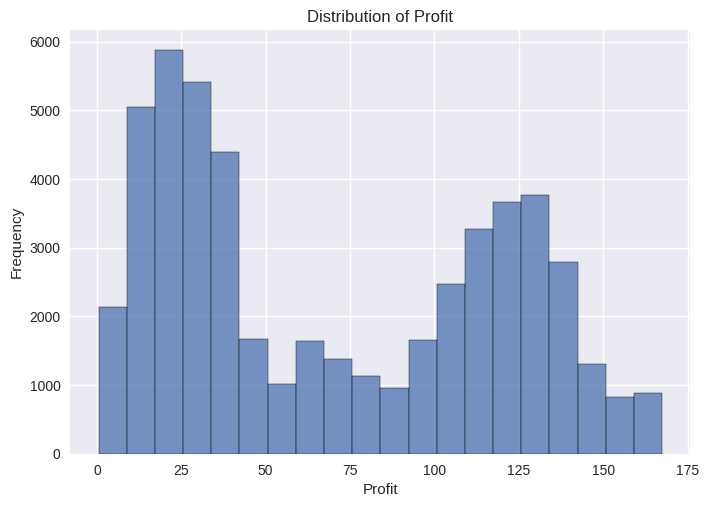

In [49]:
# Гістограма візуалізації розподілу прибутку
plt.style.use("seaborn-v0_8")
sns.histplot(x="profit", bins=20, data=sales_data)
plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()

Найбільша кількість спостережень зосереджена в діапазоні прибутку приблизно 20–25. Із підвищенням прибутку частота спостережень поступово зменшується. Значення з високим прибутком трапляються рідше, ніж із низьким і середнім.

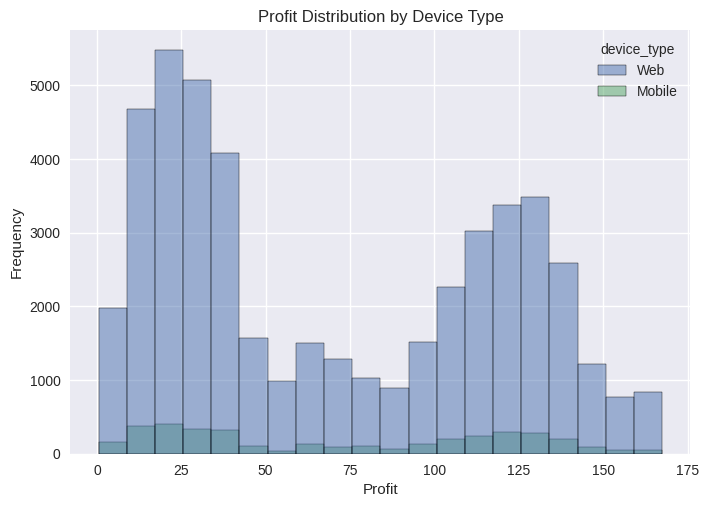

In [50]:
# Гістограма прибутку продажів через веббраузер та мобільний додаток (hue)
plt.style.use("seaborn-v0_8")
sns.histplot(x="profit", hue="device_type", bins=20, data=sales_data)
plt.title("Profit Distribution by Device Type")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()

Розподіл прибутку для продажів через веббраузер і мобільний додаток має схожу тенденцію. Найбільша кількість спостережень припадає на нижчі та середні значення прибутку. В обох каналах високі значення прибутку трапляються рідше.

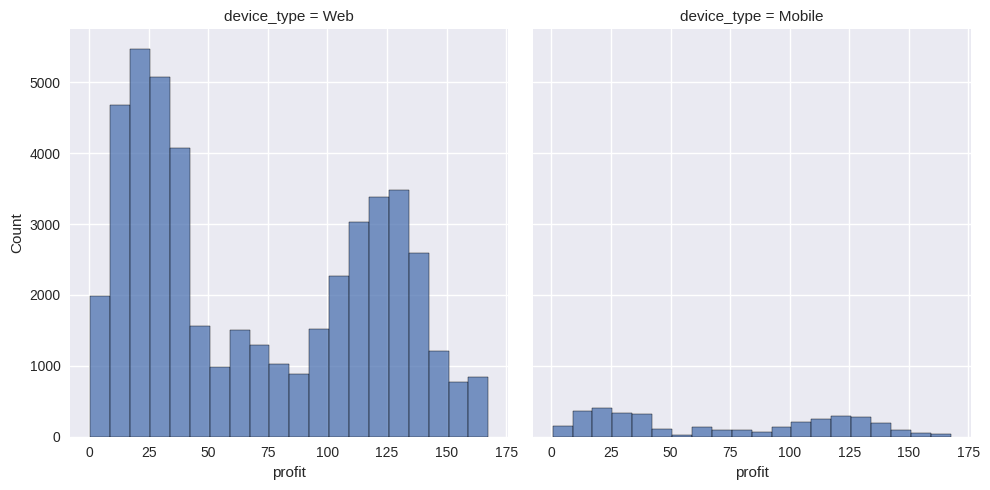

In [51]:
# Гістограма прибутку продажів через веббраузер та мобільний додаток (col)
plt.style.use("seaborn-v0_8")
sns.displot(x="profit", col="device_type", data=sales_data, bins=20)
plt.show()

Окремі гістограми дають змогу краще порівняти розподіл прибутку для кожного каналу продажів. В обох випадках найбільше спостережень зосереджено в діапазоні нижчих і середніх значень прибутку, тоді як високі значення зустрічаються рідше.

In [52]:
# Перетворення даних
sales_data["order_date"] = pd.to_datetime(sales_data["order_date"])
print(sales_data["order_date"].dtype)

datetime64[ns]


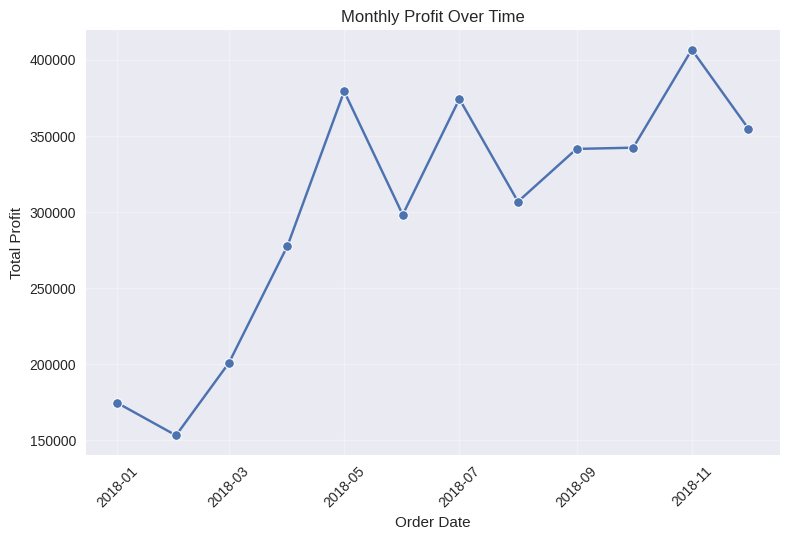

In [53]:
# Групування загального прибутку за місяцями
monthly_profit = (sales_data.groupby(sales_data["order_date"].dt.to_period("M"))["profit"].sum().reset_index())
monthly_profit["order_date"] = monthly_profit["order_date"].dt.to_timestamp()

# Лінійний графік загального прибутку за місяцями
plt.style.use("seaborn-v0_8")
sns.lineplot(x="order_date", y="profit", marker="o", data=monthly_profit,)
plt.title("Monthly Profit Over Time")
plt.xlabel("Order Date")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Лінійний графік демонструє зміну загального прибутку за місяцями. Протягом 2018 року спостерігаються коливання прибутку: після періодів зростання та спаду найвищого значення досягнуто в листопаді, а в грудні відбулося незначне зниження.

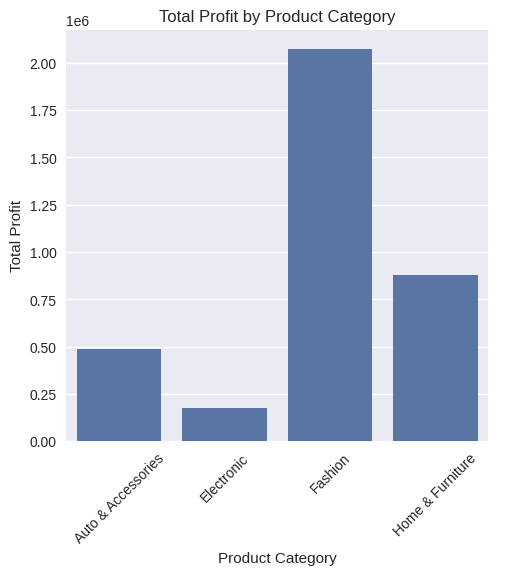

In [54]:
# Групування загального прибутку за категоріями товарів
profit_by_category = (sales_data.groupby("product_category", as_index=False)["profit"].sum())

# Стовпчикова діаграма загального прибутку за категоріями товарів
plt.style.use("seaborn-v0_8")
sns.catplot(x="product_category", y="profit", kind="bar", data=profit_by_category)
plt.title("Total Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.show()

Найбільший загальний прибуток серед категорій товарів приносить Fashion, тоді як найменший — Electronics. Це свідчить про відмінності в прибутковості різних товарних категорій.

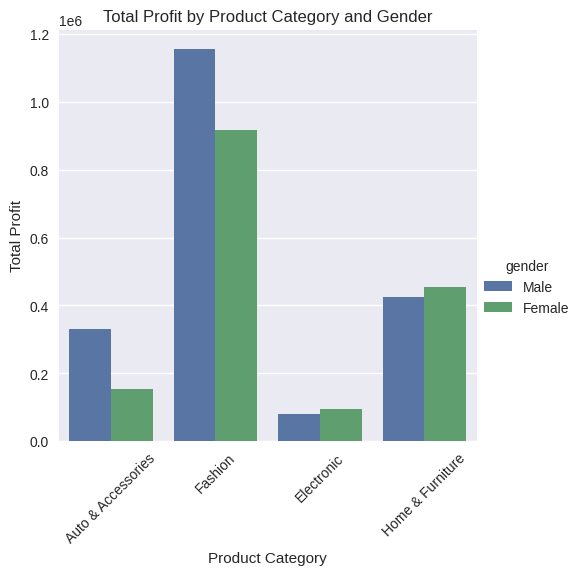

In [55]:
# Загальний прибуток за категоріями товарів і статтю
plt.style.use("seaborn-v0_8")
sns.catplot(x="product_category", y="profit", hue="gender", kind="bar", estimator="sum", data=sales_data, errorbar=None)
plt.title("Total Profit by Product Category and Gender")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.show()

На графіку порівнюється загальний прибуток у різних категоріях товарів окремо для чоловіків і жінок. Для кожної категорії можна побачити внесок обох груп у загальний прибуток.

## Overall Conclusion
У ході аналізу було досліджено розподіл прибутку, його зміну в часі, а також відмінності між каналами продажів, категоріями товарів і статтю покупців. Результати показали, що прибуток має нерівномірний розподіл, а його основні характеристики та структура відрізняються залежно від категорії товару. Водночас суттєвих відмінностей між чоловіками та жінками не спостерігається. Використані графіки Seaborn допомогли наочно представити дані та виявити основні закономірності.